# Counting faces with a Haar cascade

Tiny project. The point is to count how many faces are in an image using `cv2.CascadeClassifier` (the Haar cascade XML ships with OpenCV, no model download needed). Haar cascades are old (Viola-Jones is from 2001), but they're still reasonable on frontal, well-lit faces and they run instantly on CPU.

To see how far "reasonable" goes, I score it on real photos with known face counts: the first 100 images of the WIDER FACE validation set (Yang et al., 2016, CC BY-NC-ND 4.0), read from the parquet export of `CUHK-CSE/wider_face` on Hugging Face. WIDER FACE is deliberately hard (crowds, tiny faces, blur, odd poses), so I also report a count restricted to faces at least 30 pixels wide, which is the cascade's minimum size here.

In [1]:
import cv2, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

ART = Path("artifacts"); ART.mkdir(exist_ok=True)

cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
face_cascade = cv2.CascadeClassifier(cascade_path)
print("cascade loaded:", not face_cascade.empty())

cascade loaded: True


In [2]:
def count_faces(img_bgr, scaleFactor=1.1, minNeighbors=5, minSize=(30,30)):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    # equalizing histogram helps a lot on under-exposed group photos
    gray = cv2.equalizeHist(gray)
    boxes = face_cascade.detectMultiScale(gray, scaleFactor=scaleFactor,
                                          minNeighbors=minNeighbors,
                                          minSize=minSize)
    return boxes

def draw(img_bgr, boxes):
    out = img_bgr.copy()
    for (x, y, w, h) in boxes:
        cv2.rectangle(out, (x, y), (x+w, y+h), (0, 220, 0), 2)
    cv2.putText(out, f"faces: {len(boxes)}", (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 220, 0), 2)
    return out

## Count faces on 100 real WIDER FACE photos

images: 100  labeled faces: 3430  (>=30px wide: 394)  predicted: 223
MAE vs all labeled faces:   32.31 faces per image
MAE vs faces >= 30px wide: 2.69 faces per image
exact count (>=30px):      23% of images


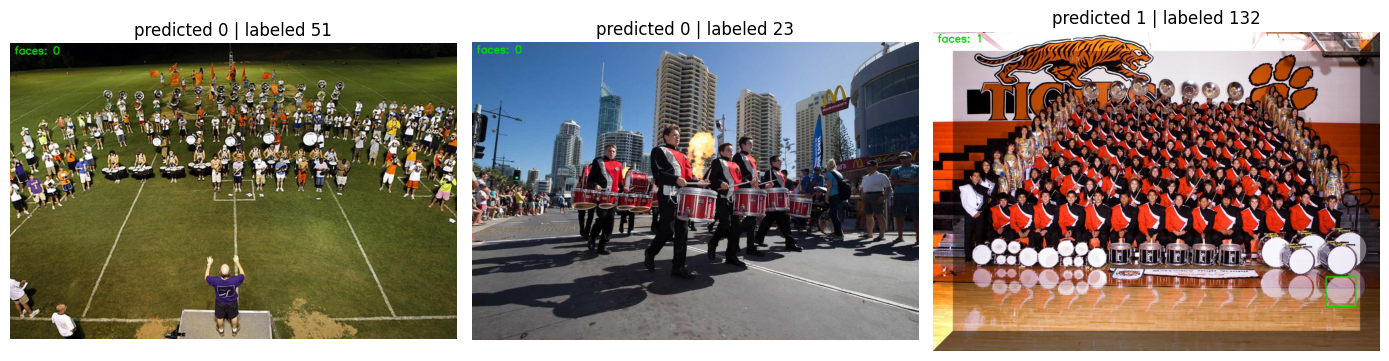

In [3]:
import io
import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem
from PIL import Image

fs = HfFileSystem()
pf = pq.ParquetFile(fs.open("datasets/CUHK-CSE/wider_face@refs%2Fconvert%2Fparquet/default/validation/0000.parquet"))
rows = pf.read_row_group(0).to_pylist()          # 100 images

records, images = [], []
for r in rows:
    img = cv2.cvtColor(np.asarray(Image.open(io.BytesIO(r["image"]["bytes"])).convert("RGB")), cv2.COLOR_RGB2BGR)
    boxes = r["faces"]["bbox"]                    # x, y, w, h per labeled face
    valid = [not inv for inv in r["faces"]["invalid"]]
    gt_all = sum(valid)
    gt_30 = sum(v and b[2] >= 30 for b, v in zip(boxes, valid))
    pred = len(count_faces(img))
    records.append({"gt_all": gt_all, "gt_30px": gt_30, "pred": pred})
    images.append((img, pred, gt_all))
res = pd.DataFrame(records)
print(f"images: {len(res)}  labeled faces: {res.gt_all.sum()}  (>=30px wide: {res.gt_30px.sum()})  predicted: {res.pred.sum()}")
print(f"MAE vs all labeled faces:   {(res.pred - res.gt_all).abs().mean():.2f} faces per image")
print(f"MAE vs faces >= 30px wide: {(res.pred - res.gt_30px).abs().mean():.2f} faces per image")
print(f"exact count (>=30px):      {(res.pred == res.gt_30px).mean():.0%} of images")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (img, pred, gt) in zip(axes, images[:3]):
    ax.imshow(cv2.cvtColor(draw(img, count_faces(img)), cv2.COLOR_BGR2RGB))
    ax.set_title(f"predicted {pred} | labeled {gt}"); ax.axis("off")
plt.tight_layout(); plt.savefig(ART/"face_count.png", dpi=110); plt.show()

## Notes

On 100 real WIDER FACE photos with 3,430 labeled faces, the cascade finds 223 faces in total. Against every labeled face it's hopeless (off by 32 faces per image on average), but that comparison is unfair: only 394 of those faces are at least 30 pixels wide, and the rest are crowd-scale faces the cascade can't see at this `minSize`. Against the 30-pixel-plus faces it's off by 2.7 faces per image and gets the exact count on 23% of photos. Since it predicts fewer faces than that total, some of those errors are misses (side profiles, partly hidden faces) and some are false positives on textures, and I'd need box-level matching to split them.

The cascade is sensitive to `scaleFactor` and `minNeighbors`. I'm using `(1.1, 5)`, which is the OpenCV docs default. Crank `minNeighbors` up if you're getting false positives on textures (curtains, brick walls).

For any serious face counting in 2026 you'd want a learned detector (RetinaFace, SCRFD or a YOLO face model), and on WIDER FACE those are the models the benchmark was built to separate. The Haar cascade is two lines of code and a free first pass, which is the whole point.